In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from scipy import stats
from scipy.linalg import expm

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# ДЗ 4. Марковські моделі: доступність API gateway (CTMC)

Варіант 16 -- трек B

Виконав: Олег Басистий

## 1. Постановка і прогноз

### Опис системи

API gateway -- єдина точка входу зовнішніх запитів до сервісів. У кожен момент часу gateway перебуває рівно в одному з трьох станів:

| Стан | Зміст | Для KPI |
|---|---|---|
| S0 | повна працездатність | доступний |
| S1 | деградований режим: запити обслуговуються, але повільно або з частиною помилок | доступний |
| S2 | недоступність | недоступний |

Час неперервний, одиниця -- година. Інтенсивності переходів задано в 1/год. Стейкхолдер: власник сервісу та SRE-команда, що відповідає за SLO доступності.

### Правило спостереження

Стан визначається щохвилини за synthetic health-check (проба кожні 10 с) і метриками gateway. Правила перевіряються в порядку S2 → S1 → S0, тому кожна хвилина належить рівно одному стану:

- S2 -- health-check не проходить у 3 послідовних пробах або частка 5xx $\ge 50$ %;
- S1 -- health-check проходить, але p95 затримки вища за SLO (наприклад, 300 мс) або частка 5xx від 1 до 50 %;
- S0 -- усе інше: health-check проходить, p95 у межах SLO, 5xx < 1 %.

Зміна класу між сусідніми хвилинами -- подія переходу в журналі.

### Практичне запитання

Яка довгострокова доступність gateway і скільки годин простою очікувати за умовний 720-годинний місяць? Як поводиться доступність у перші 24 год після старту в S0? Наскільки зменшиться простій, якщо прискорити відновлення S2 → S1 на 25 %?

### Навчальний приклад журналу подій

Три записи журналу і кінець спостереження $t_{end} = 20$ год. Для CTMC накопичуємо час перебування $T_i$ у кожному стані та лічильники переходів $N_{ij}$, а оцінка інтенсивності -- $\hat q_{ij} = N_{ij} / T_i$.

In [2]:
event_log = pd.DataFrame({"t, h": [12.4, 15.1, 15.9],
                          "state before": ["S0", "S1", "S2"],
                          "state after": ["S1", "S2", "S1"]})
display(event_log)

,"t, h",state before,state after
0,12.4,S0,S1
1,15.1,S1,S2
2,15.9,S2,S1


In [3]:
def estimate_rates(log, start_state, t_end, states):
    """
    Sojourn times T_i, transition counts N_ij and q_ij = N_ij / T_i from an event log.
    """
    time_in = dict.fromkeys(states, 0.0)
    counts = pd.DataFrame(0, index=states, columns=states)
    t_prev, current = 0.0, start_state
    for _, e in log.iterrows():
        assert e["state before"] == current, "log is inconsistent"
        time_in[current] += e["t, h"] - t_prev
        counts.loc[e["state before"], e["state after"]] += 1
        t_prev, current = e["t, h"], e["state after"]
    time_in[current] += t_end - t_prev
    T = pd.Series(time_in)
    return T, counts, counts.div(T, axis=0)

In [4]:
T_demo, N_demo, q_demo = estimate_rates(event_log, "S0", 20.0, ["S0", "S1", "S2"])

In [5]:
print("T_i, h:", T_demo.round(2).to_dict())
print("N_ij:")
display(N_demo)
print("q_ij estimate, 1/h:")
display(q_demo.round(3))

T_i, h: {'S0': 12.4, 'S1': 6.8, 'S2': 0.8}
N_ij:


,S0,S1,S2
S0,0,1,0
S1,0,0,1
S2,0,1,0


q_ij estimate, 1/h:


,S0,S1,S2
S0,0.0,0.081,0.000
S1,0.0,0.000,0.147
S2,0.0,1.250,0.000


S1 спостерігався двома відрізками, $2{,}7 + 4{,}1 = 6{,}8$ год, тому $\hat q_{12} = 1/6{,}8 \approx 0{,}147$ 1/год. Одна подія на стан дає дуже грубу оцінку, тож для реальних $q_{ij}$ потрібен журнал за багато місяців. Числові інтенсивності варіанта задані, і далі використовуються саме вони.

### Прогноз до обчислень

*Записано до обчислень, після запуску не редагувався.*

1. Середній час перебування: S0 -- $1/0{,}025 = 40$ год, S1 -- $1/0{,}141 \approx 7$ год, S2 -- $1/0{,}215 \approx 4{,}7$ год. Із S1 система у $0{,}130/0{,}141 \approx 92$ % випадків повертається в S0. Отже, домінуватиме S0 (близько 80-85 % часу), S1 займе близько 15 %, S2 -- менше 1 %.
2. Ланцюг лінійний (S0 ⇄ S1 ⇄ S2), тому $\pi_2 / \pi_1 = q_{12} / q_{21}$. Збільшення $q_{21}$ на 25 % скоротить середню тривалість простою з 4,7 до 3,7 год, а частота відмов майже не зміниться. Очікую, що простій зменшиться приблизно в 1,25 раза, тобто на 20 %.
3. Через старт у S0 доступність $A(t)$ спадатиме від 1 до $A_\infty$, і за 24 год ще буде трохи вищою за $A_\infty$.

## 2. Паспорт моделі

| Елемент | Позначення | Значення | Одиниці | Джерело |
|---|---|---|---|---|
| Стани | $S = \{S0, S1, S2\}$ | S0, S1 -- доступні, S2 -- недоступний | -- | умова варіанта, правило з розділу 1 |
| Час | $t \ge 0$ | перехідний аналіз $0..T$, $T = 24$; місяць $H = 720$ | год | умова варіанта |
| Інтенсивності | $q_{01}, q_{10}, q_{12}, q_{21}$ | 0,025; 0,130; 0,011; 0,215 | 1/год | умова варіанта (синтетичні); у реальності -- журнал подій |
| Заборонені переходи | $q_{02} = q_{20} = 0$ | немає прямого падіння S0 → S2 і повного відновлення S2 → S0 | 1/год | умова варіанта |
| Генератор | $Q$ | $q_{ij}$ поза діагоналлю, $q_{ii} = -\sum_{j \ne i} q_{ij}$ | 1/год | -- |
| Початковий розподіл | $p(0)$ | $(1,\ 0,\ 0)$ -- старт у повній працездатності | -- | умова варіанта |
| Перехідний KPI | $A(t) = 1 - p_2(t)$ | імовірність бути доступним у момент $t$ | частка | -- |
| Стаціонарні KPI | $A_\infty = 1 - \pi_2$, $D_{month} = 720\,\pi_2$ | довгострокова частка часу доступності, простій за місяць | частка, год/міс | -- |
| Сценарій | $q_{21}' = 1{,}25\,q_{21}$ | 0,26875 | 1/год | умова варіанта |
| Джерело спостережень | -- | health-check, метрики gateway (Prometheus), журнал інцидентів | -- | розділ 8 |

### Математична модель

$$
p(t) = p(0)\, e^{Qt}, \qquad \pi Q = 0, \qquad \sum_i \pi_i = 1
$$

$$
A_\infty = \pi_0 + \pi_1 = 1 - \pi_2, \qquad D_{month} = 720\, \pi_2 \ \text{год}
$$

Тут $p(t) = \big(p_0(t),\ p_1(t),\ p_2(t)\big)$ -- імовірності станів у момент $t$ (перехідний режим), $\pi$ -- стаціонарний розподіл, $A(t) = 1 - p_2(t)$.

### Припущення

1. Марковість: майбутнє залежить лише від поточного стану, а не від того, скільки часу система вже в ньому чи як сюди потрапила. Еквівалентно: час перебування в стані експоненційний.
2. Однорідність у часі: $Q$ не залежить від $t$, зокрема від години доби, дня тижня чи моменту деплою.
3. Стаціонарність параметрів: інтенсивності не мають тренду протягом усього горизонту (місяць, $10^6$ год імітації), тобто немає старіння системи чи поступових покращень.
4. Стани спостерігаються без помилок, а короткі збої, коротші за вікно класифікації (1 хв), не фіксуються.

## 3. Генератор Q

$$
Q = \begin{pmatrix}
-q_{01} & q_{01} & 0 \\
q_{10} & -(q_{10} + q_{12}) & q_{12} \\
0 & q_{21} & -q_{21}
\end{pmatrix}
= \begin{pmatrix}
-0{,}025 & 0{,}025 & 0 \\
0{,}130 & -0{,}141 & 0{,}011 \\
0 & 0{,}215 & -0{,}215
\end{pmatrix}
\quad [1/\text{год}]
$$

Позадіагональний $q_{ij}$ -- інтенсивність, а не ймовірність: за малий інтервал $\Delta t$ імовірність переходу $i \to j$ дорівнює $q_{ij} \Delta t + o(\Delta t)$, і $q_{ij}$ може бути більшим за 1.

Чому $-q_{ii}$ -- сумарна інтенсивність виходу: зі стану $i$ кожен дозволений перехід $j$ має свій незалежний експоненційний «годинник» з інтенсивністю $q_{ij}$. Система виходить зі стану, коли спрацює перший із них, а мінімум незалежних $\text{Exp}(q_{ij})$ розподілений як $\text{Exp}(\sum_{j \ne i} q_{ij}) = \text{Exp}(-q_{ii})$. Тому час перебування $\tau_i \sim \text{Exp}(-q_{ii})$, його середнє $\mathbb{E}\,\tau_i = 1/(-q_{ii})$, а наступний стан -- $j$ з імовірністю $q_{ij} / (-q_{ii})$. Рядкові суми $Q$ дорівнюють 0, бо $\sum_j p_{ij}(\Delta t) = 1$.

In [6]:
STATES = ["S0", "S1", "S2"]
UP_STATES = [0, 1]   # S0, S1 count as available
DOWN = 2             # S2 -- unavailable

RATES = {(0, 1): 0.025,   # degradation
         (1, 0): 0.130,   # full recovery
         (1, 2): 0.011,   # degraded -> unavailable
         (2, 1): 0.215}   # partial recovery, 1/h
P0 = np.array([1.0, 0.0, 0.0])

T_HORIZON = 24          # h, transient analysis
MONTH_HOURS = 720
SCENARIO_FACTOR = 1.25  # q_21 * 1.25
TOL = 1e-10
CONTROL = {"A(24)": 0.9925, "A_inf": 0.9918, "downtime": 5.89, "downtime scenario": 4.72}

In [7]:
def build_generator(rates, n_states):
    """
    Q from off-diagonal rates {(i, j): q_ij}; diagonal q_ii = -sum_j q_ij.
    """
    Q = np.zeros((n_states, n_states))
    for (i, j), q in rates.items():
        Q[i, j] = q
    np.fill_diagonal(Q, -Q.sum(axis=1))
    return Q

In [8]:
def is_irreducible(Q):
    """
    Every state is reachable from every other one along the graph of q_ij > 0.
    """
    n = Q.shape[0]
    reach = (Q > 0) | np.eye(n, dtype=bool)
    for _ in range(n):
        reach = (reach.astype(int) @ reach.astype(int)) > 0
    return bool(reach.all())

In [9]:
def check_generator(Q, tol=TOL):
    off = Q[~np.eye(Q.shape[0], dtype=bool)]
    return {"off-diagonal >= 0": bool((off >= -tol).all()),
            "diagonal < 0": bool((np.diag(Q) < 0).all()),
            "row sums = 0": bool(np.allclose(Q.sum(axis=1), 0, atol=tol)),
            "irreducible": is_irreducible(Q)}

In [10]:
Q = build_generator(RATES, len(STATES))
checks = check_generator(Q)

In [11]:
print("Q, 1/h:")
display(pd.DataFrame(Q, index=STATES, columns=STATES))
print(checks)
assert all(checks.values())

Q, 1/h:


,S0,S1,S2
S0,-0.025,0.025,0.000
S1,0.130,-0.141,0.011
S2,0.000,0.215,-0.215


{'off-diagonal >= 0': True, 'diagonal < 0': True, 'row sums = 0': True, 'irreducible': True}


In [12]:
exit_rate = -np.diag(Q)
jump = (Q - np.diag(np.diag(Q))) / exit_rate[:, None]   # embedded jump chain
sojourn = pd.DataFrame({"-q_ii, 1/h": exit_rate,
                        "mean sojourn 1/(-q_ii), h": 1 / exit_rate,
                        **{f"P(next = {s})": jump[:, j] for j, s in enumerate(STATES)}},
                       index=STATES)

In [13]:
display(sojourn.round(4))
assert np.allclose(jump.sum(axis=1), 1)

,"-q_ii, 1/h","mean sojourn 1/(-q_ii), h",P(next = S0),P(next = S1),P(next = S2)
S0,0.025,40.0000,0.000,1.0,0.000
S1,0.141,7.0922,0.922,0.0,0.078
S2,0.215,4.6512,0.000,1.0,0.000


Фізичний зміст діагоналі:

- $q_{00} = -0{,}025$: із S0 виходять лише через деградацію, повна працездатність триває в середньому 40 год.
- $q_{11} = -0{,}141$: S1 конкурують два виходи, відновлення (0,130) і відмова (0,011). Деградація триває в середньому 7,1 год і в 92,2 % випадків закінчується поверненням у S0, а у 7,8 % -- недоступністю.
- $q_{22} = -0{,}215$: із S2 є лише часткове відновлення, середня тривалість простою (MTTR до S1) -- 4,65 год.

**Умова єдиного $\pi$.** Простір станів скінченний, а ланцюг незвідний (S0 ⇄ S1 ⇄ S2, перевірено кодом). Тоді існує єдиний стаціонарний розподіл $\pi$ з $\pi_i > 0$, і $p(t) \to \pi$ для будь-якого $p(0)$. Періодичності в неперервному часі не буває, тому окремої перевірки аперіодичності не потрібно.

## 4. Перехідний режим

$$p(t) = p(0)\, e^{Qt}, \qquad A(t) = p_0(t) + p_1(t) = 1 - p_2(t).$$

Обчислюємо $p(t)$ через `scipy.linalg.expm` на сітці $t = 0..24$ год з кроком 0,1 год і в кожній точці перевіряємо невід'ємність і нормування.

In [14]:
def transient(Q, p0, t_grid, tol=TOL):
    """
    p(t) = p(0) expm(Q t) for every t in the grid, with a check of each row.
    """
    p = np.array([p0 @ expm(Q * t) for t in t_grid])
    assert (p >= -tol).all(), "negative probability"
    assert np.allclose(p.sum(axis=1), 1, atol=1e-9), "p(t) does not sum to 1"
    return np.clip(p, 0, None)

In [15]:
t_grid = np.round(np.arange(0, T_HORIZON + 1e-9, 0.1), 1)
p_t = transient(Q, P0, t_grid)
A_t = 1 - p_t[:, DOWN]
p_24 = p_t[-1]

In [16]:
transient_table = pd.DataFrame(p_t, index=t_grid, columns=[f"p_{s}(t)" for s in STATES])
transient_table["A(t)"] = A_t
transient_table.index.name = "t, h"

In [17]:
display(transient_table.loc[[0, 1, 2, 4, 6, 8, 12, 16, 20, 24]].round(5))

,p_S0(t),p_S1(t),p_S2(t),A(t)
"t, h",,,,
0.0,1.00000,0.00000,0.00000,1.00000
1.0,0.97684,0.02304,0.00012,0.99988
2.0,0.95697,0.04260,0.00043,0.99957
4.0,0.92525,0.07340,0.00135,0.99865
6.0,0.90176,0.09583,0.00242,0.99758
8.0,0.88429,0.11226,0.00345,0.99655
12.0,0.86151,0.13333,0.00516,0.99484
16.0,0.84871,0.14496,0.00633,0.99367
20.0,0.84146,0.15146,0.00708,0.99292


In [18]:
print("p(24) =", dict(zip(STATES, p_24.round(5).tolist())))
print(f"A(24) = {A_t[-1]:.4f}")
assert t_grid[-1] == T_HORIZON
assert round(A_t[-1], 4) == CONTROL["A(24)"]

p(24) = {'S0': 0.83735, 'S1': 0.15512, 'S2': 0.00753}
A(24) = 0.9925


In [19]:
S0_COLOR, S1_COLOR, S2_COLOR = "#1baf7a", "#d99a1e", "#e34948"
STATE_COLORS = [S0_COLOR, S1_COLOR, S2_COLOR]
INK = "#52514e"
SCENARIO_COLOR = "#2a78d6"

In [20]:
def finish_time_axis(ax, title, ylabel, t_max=T_HORIZON, step=4):
    """
    Shared styling of the plots over time t = 0..t_max h
    """
    ax.set_title(title)
    ax.set_xlabel("t, h")
    ax.set_ylabel(ylabel)
    ax.set_xlim(0, t_max)
    ax.set_xticks(range(0, t_max + 1, step))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

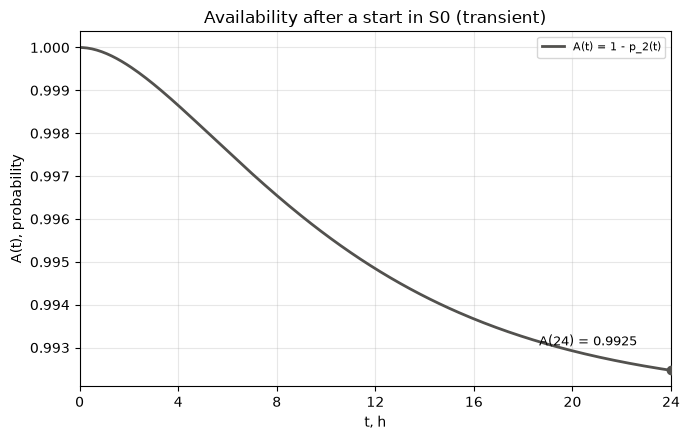

In [21]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(t_grid, A_t, color=INK, lw=2, label="A(t) = 1 - p_2(t)")
ax.scatter(T_HORIZON, A_t[-1], color=INK, zorder=3)
ax.annotate(f"A(24) = {A_t[-1]:.4f}", (T_HORIZON, A_t[-1]), textcoords="offset points",
            xytext=(-95, 18), fontsize=9)
finish_time_axis(ax, "Availability after a start in S0 (transient)", "A(t), probability")
plt.tight_layout()
plt.show()

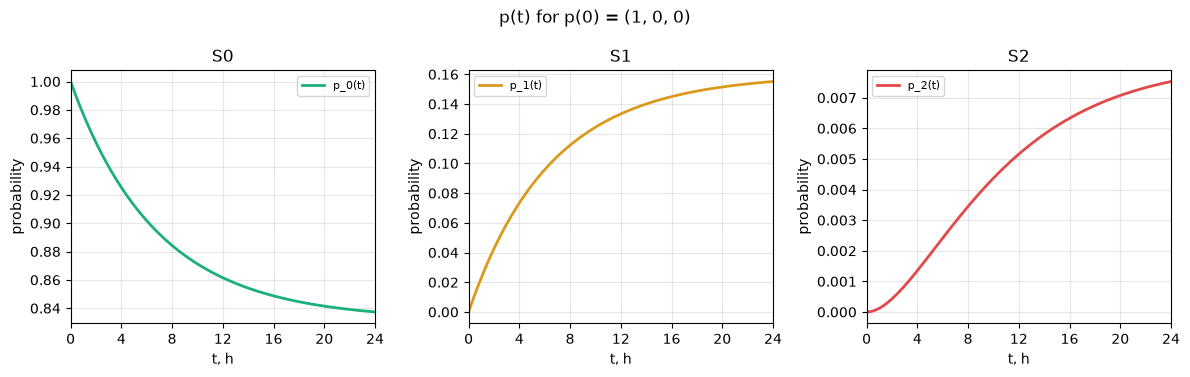

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for i, ax in enumerate(axes):
    ax.plot(t_grid, p_t[:, i], color=STATE_COLORS[i], lw=2, label=f"p_{i}(t)")
    finish_time_axis(ax, STATES[i], "probability")
fig.suptitle("p(t) for p(0) = (1, 0, 0)")
plt.tight_layout()
plt.show()

За 24 год імовірність деградації $p_1$ зростає з 0 до 0,155, а $p_2$ -- до 0,0075. $A(t)$ монотонно спадає від 1, бо система стартує в найкращому стані, і $A(24) = 0{,}9925$.

## 5. Стаціонарний режим

$\pi$ -- розв'язок $\pi Q = 0$, $\sum_i \pi_i = 1$. Система $Q^\top \pi^\top = 0$ має ранг 2, тому одне з рівнянь замінюємо на нормування.

In [23]:
def stationary(Q):
    """
    Solve pi Q = 0 with sum(pi) = 1: the last balance equation is replaced by normalisation.
    """
    n = Q.shape[0]
    A = np.vstack([Q.T[:-1], np.ones(n)])
    b = np.zeros(n)
    b[-1] = 1
    return np.linalg.solve(A, b)

In [24]:
def stationary_kpi(Q):
    pi = stationary(Q)
    return {"pi": pi, "A_inf": 1 - pi[DOWN], "downtime": MONTH_HOURS * pi[DOWN]}

In [25]:
base = stationary_kpi(Q)
pi = base["pi"]

In [26]:
print("pi =", dict(zip(STATES, pi.round(6).tolist())))
print(f"max |pi Q| = {np.abs(pi @ Q).max():.2e}, sum(pi) = {pi.sum():.12f}")
assert np.allclose(pi @ Q, 0, atol=TOL)
assert np.isclose(pi.sum(), 1, atol=TOL) and (pi > 0).all()

pi = {'S0': 0.831845, 'S1': 0.15997, 'S2': 0.008185}
max |pi Q| = 2.68e-18, sum(pi) = 1.000000000000


In [27]:
# independent checks: detailed balance of a birth-death chain and p(t) for a large t
assert np.isclose(pi[1] / pi[0], RATES[(0, 1)] / RATES[(1, 0)])
assert np.isclose(pi[2] / pi[1], RATES[(1, 2)] / RATES[(2, 1)])
assert np.allclose(P0 @ expm(Q * 1000), pi, atol=1e-9)

In [28]:
t_long = np.arange(0, 72.01, 0.25)
A_long = 1 - transient(Q, P0, t_long)[:, DOWN]

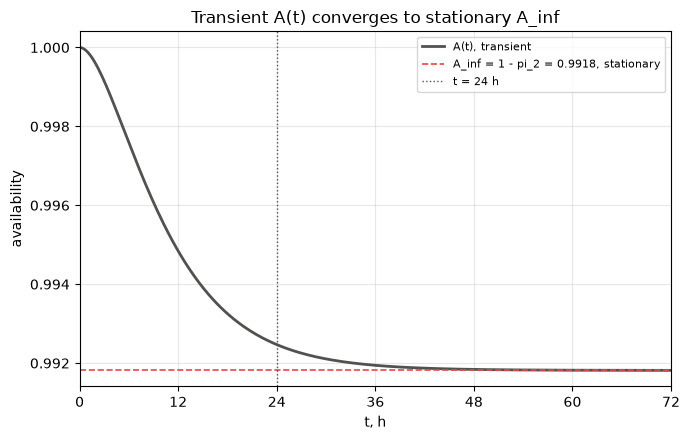

In [29]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(t_long, A_long, color=INK, lw=2, label="A(t), transient")
ax.axhline(base["A_inf"], color=S2_COLOR, ls="--", lw=1.2, label=f"A_inf = 1 - pi_2 = {base['A_inf']:.4f}, stationary")
ax.axvline(T_HORIZON, color=INK, ls=":", lw=1, label="t = 24 h")
finish_time_axis(ax, "Transient A(t) converges to stationary A_inf", "availability", t_max=72, step=12)
plt.tight_layout()
plt.show()

In [30]:
gap = -np.sort(np.linalg.eigvals(Q).real)[-2]
dist_24 = np.abs(p_24 - pi).sum()

In [31]:
print(f"spectral gap = {gap:.4f} 1/h, relaxation time 1/gap = {1 / gap:.2f} h")
print(f"||p(24) - pi||_1 = {dist_24:.5f}")

spectral gap = 0.1386 1/h, relaxation time 1/gap = 7.21 h
||p(24) - pi||_1 = 0.01100


Перехідний і стаціонарний результати -- різні величини. $A(24) = 0{,}9925$ -- імовірність бути доступним через 24 год після старту в S0, а $A_\infty = 0{,}9918$ -- довгострокова частка часу. За 24 год система ще не досягла $\pi$: $p_2(24) = 0{,}0075$ проти $\pi_2 = 0{,}0082$. Відхилення $\|p(t) - \pi\|_1$ згасає як $e^{-0{,}139\,t}$ (час релаксації $\approx 7{,}2$ год), тож після 2-3 діб стартовий стан уже не впливає на доступність.

In [32]:
stationary_table = pd.DataFrame({"pi_i": pi,
                                 "hours per 720 h": MONTH_HOURS * pi,
                                 "mean sojourn, h": 1 / exit_rate,
                                 "available": [i in UP_STATES for i in range(len(STATES))]},
                                index=STATES)
outages_per_month = MONTH_HOURS * pi[1] * RATES[(1, 2)]

In [33]:
display(stationary_table.round(4))

,pi_i,hours per 720 h,"mean sojourn, h",available
S0,0.8318,598.9286,40.0000,True
S1,0.1600,115.1786,7.0922,True
S2,0.0082,5.8929,4.6512,False


In [34]:
print(f"A_inf = {base['A_inf']:.4f} = {100 * base['A_inf']:.2f} %")
print(f"D_month = 720 * pi_2 = {base['downtime']:.2f} h/month")
print(f"= {outages_per_month:.2f} outages/month x {1 / RATES[(2, 1)]:.2f} h mean outage")
assert round(base["A_inf"], 4) == CONTROL["A_inf"]
assert round(base["downtime"], 2) == CONTROL["downtime"]
assert np.isclose(base["downtime"], outages_per_month / RATES[(2, 1)])

A_inf = 0.9918 = 99.18 %
D_month = 720 * pi_2 = 5.89 h/month
= 1.27 outages/month x 4.65 h mean outage


У довгостроковому режимі gateway 83,2 % часу повністю працездатний, 16,0 % (115 год/міс) деградований і 0,82 % недоступний. $A_\infty = 99{,}18$ %, очікуваний простій -- 5,89 год за 720-годинний місяць. Це в середньому 1,27 відмови на місяць по 4,65 год кожна. S1 зараховано до доступних, але 115 год на місяць клієнти бачать повільні відповіді або помилки, і $A_\infty$ цього не показує.

## 6. Сценарій: $q_{21}$ на 25 % більше

Змінюється лише інтенсивність часткового відновлення: $q_{21}' = 1{,}25 \cdot 0{,}215 = 0{,}26875$ 1/год. Діагональ $q_{22}$ перераховується з нового рядка, інші інтенсивності і $p(0)$ ті самі.

In [35]:
SCENARIO_RATES = {**RATES, (2, 1): SCENARIO_FACTOR * RATES[(2, 1)]}
Q_scen = build_generator(SCENARIO_RATES, len(STATES))

In [36]:
display(pd.DataFrame(Q_scen, index=STATES, columns=STATES))
assert all(check_generator(Q_scen).values())
assert np.array_equal(Q[:2], Q_scen[:2])   # only row S2 changed

,S0,S1,S2
S0,-0.025,0.02500,0.00000
S1,0.130,-0.14100,0.01100
S2,0.000,0.26875,-0.26875


In [37]:
scen = stationary_kpi(Q_scen)
A_t_scen = 1 - transient(Q_scen, P0, t_grid)[:, DOWN]

kpi = pd.DataFrame({
    "base": [RATES[(2, 1)], 1 / RATES[(2, 1)], *pi, A_t[-1], base["A_inf"], base["downtime"]],
    "scenario": [SCENARIO_RATES[(2, 1)], 1 / SCENARIO_RATES[(2, 1)], *scen["pi"],
                 A_t_scen[-1], scen["A_inf"], scen["downtime"]]},
    index=["q_21, 1/h", "mean outage 1/q_21, h", "pi_0", "pi_1", "pi_2",
           "A(24)", "A_inf", "D_month, h/month"])
kpi["abs change"] = kpi["scenario"] - kpi["base"]
kpi["rel change, %"] = 100 * kpi["abs change"] / kpi["base"]

In [38]:
display(kpi.round(5))
assert np.allclose(scen["pi"] @ Q_scen, 0, atol=TOL) and np.isclose(scen["pi"].sum(), 1)
assert round(scen["downtime"], 2) == CONTROL["downtime scenario"]

,base,scenario,abs change,"rel change, %"
"q_21, 1/h",0.21500,0.26875,0.05375,25.00000
"mean outage 1/q_21, h",4.65116,3.72093,-0.93023,-20.00000
pi_0,0.83185,0.83321,0.00136,0.16396
pi_1,0.15997,0.16023,0.00026,0.16396
pi_2,0.00818,0.00656,-0.00163,-19.86883
A(24),0.99247,0.99384,0.00137,0.13843
A_inf,0.99182,0.99344,0.00163,0.16396
"D_month, h/month",5.89286,4.72202,-1.17084,-19.86883


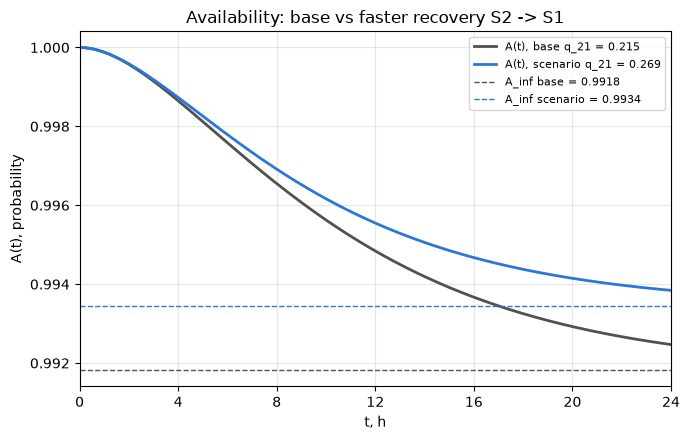

In [39]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(t_grid, A_t, color=INK, lw=2, label="A(t), base q_21 = 0.215")
ax.plot(t_grid, A_t_scen, color=SCENARIO_COLOR, lw=2, label="A(t), scenario q_21 = 0.269")
ax.axhline(base["A_inf"], color=INK, ls="--", lw=1, label=f"A_inf base = {base['A_inf']:.4f}")
ax.axhline(scen["A_inf"], color=SCENARIO_COLOR, ls="--", lw=1, label=f"A_inf scenario = {scen['A_inf']:.4f}")
finish_time_axis(ax, "Availability: base vs faster recovery S2 -> S1", "A(t), probability")
plt.tight_layout()
plt.show()

Прискорення відновлення S2 → S1 на 25 % зменшує місячний простій з 5,89 до 4,72 год ($-1{,}17$ год, $-19{,}9$ %), а $A_\infty$ зростає з 99,18 до 99,34 %. Ефект майже точно дорівнює $1 - 1/1{,}25 = 20$ %: середня відмова коротшає з 4,65 до 3,72 год, а частота відмов не змінюється, бо $q_{01}, q_{10}, q_{12}$ ті самі. $\pi_0$ і $\pi_1$ зростають на однакові 0,16 %, бо їх співвідношення $q_{01}/q_{10}$ не змінилося, і час, звільнений із S2, розподіляється між ними пропорційно. У перехідному режимі різниця мала (за 24 год відмова ще рідкісна подія), а основний ефект -- у довгостроковій частці часу.

## 7. Верифікація імітацією

Подієва імітація CTMC, незалежна від `expm` і розв'язання $\pi Q = 0$: у стані $i$ розігруємо час перебування $\tau \sim \text{Exp}(-q_{ii})$ і наступний стан $j$ з імовірністю $q_{ij}/(-q_{ii})$.

- seed = 42, старт у S0;
- розігрів 1 000 год відкидаємо, це понад 100 часів релаксації (7,2 год), тому вплив $p(0)$ зникає;
- горизонт вимірювання $10^6$ год. На мінімальних $10^5$ год відмов лише близько 180, і 95 % інтервал виходить близько $\pm 20$ % від $\pi_2$, тому горизонт збільшено в 10 разів;
- 20 часових блоків по 50 000 год. У кожному блоці рахуємо частку часу в S2.

Послідовні моменти часу залежні: відмова триває години, тому стан у сусідні моменти однаковий. Звичайна формула $s/\sqrt{n}$ для всіх подій чи годин недооцінила б похибку. Блоки по 50 000 год значно довші за час релаксації, тому частки в блоках майже незалежні, і 95 % інтервал будуємо методом середніх за блоками: $\bar f \pm t_{0{,}975;\,19} \cdot s_f / \sqrt{20}$.

In [40]:
SEED = 42
WARMUP = 1_000         # h
SIM_HORIZON = 1_000_000  # h, after warm-up
N_BLOCKS = 20

In [41]:
def simulate_ctmc(Q, start, t_end, rng):
    """
    Event-driven CTMC path: jump times (starting at 0) and the state entered at each of them.
    """
    n = Q.shape[0]
    times, states = [0.0], [start]
    t, s = 0.0, start
    while t < t_end:
        out = -Q[s, s]
        t += rng.exponential(1 / out)
        s = rng.choice(n, p=np.clip(Q[s], 0, None) / out)
        times.append(t)
        states.append(s)
    return np.array(times), np.array(states)

In [42]:
def block_fractions(times, states, state, t_from, t_to, n_blocks):
    """
    Share of time spent in `state` inside each of n_blocks equal time blocks of [t_from, t_to].
    """
    edges = np.linspace(t_from, t_to, n_blocks + 1)
    start, end = times[:-1], times[1:]
    in_state = states[:-1] == state
    start, end = start[in_state], end[in_state]
    return np.array([np.clip(np.minimum(end, hi) - np.maximum(start, lo), 0, None).sum() / (hi - lo)
                     for lo, hi in zip(edges[:-1], edges[1:])])

In [43]:
def batch_means_ci(x, level=0.95):
    n = len(x)
    half = stats.t.ppf((1 + level) / 2, n - 1) * x.std(ddof=1) / np.sqrt(n)
    return x.mean(), half

In [44]:
rng = np.random.default_rng(SEED)
sim_times, sim_states = simulate_ctmc(Q, 0, WARMUP + SIM_HORIZON, rng)
t_from, t_to = WARMUP, WARMUP + SIM_HORIZON
n_outages = int(((sim_states[1:] == DOWN) & (sim_times[1:] >= t_from) & (sim_times[1:] < t_to)).sum())

In [45]:
print(f"seed = {SEED}, warm-up = {WARMUP} h, horizon = {SIM_HORIZON} h, blocks = {N_BLOCKS} x {SIM_HORIZON // N_BLOCKS} h")
print(f"jumps simulated: {len(sim_times) - 1}, outages (entries to S2) after warm-up: {n_outages}")

seed = 42, warm-up = 1000 h, horizon = 1000000 h, blocks = 20 x 50000 h
jumps simulated: 45333, outages (entries to S2) after warm-up: 1790


In [46]:
sim_rows = []
for i, s in enumerate(STATES):
    f = block_fractions(sim_times, sim_states, i, t_from, t_to, N_BLOCKS)
    mean, half = batch_means_ci(f)
    sim_rows.append({"pi analytic": pi[i], "simulated share": mean, "95% CI low": mean - half,
                     "95% CI high": mean + half, "abs error": abs(mean - pi[i]),
                     "rel error, %": 100 * abs(mean - pi[i]) / pi[i],
                     "pi in CI": mean - half <= pi[i] <= mean + half})
verification = pd.DataFrame(sim_rows, index=STATES)

In [47]:
display(verification.round(5))
assert verification["pi in CI"].all()

,pi analytic,simulated share,95% CI low,95% CI high,abs error,"rel error, %",pi in CI
S0,0.83185,0.83006,0.82728,0.83283,0.00179,0.21521,True
S1,0.15997,0.16169,0.15924,0.16413,0.00172,1.07376,True
S2,0.00818,0.00826,0.00743,0.00908,0.00007,0.88548,True


In [48]:
f_down = block_fractions(sim_times, sim_states, DOWN, t_from, t_to, N_BLOCKS)
pi2_hat, pi2_half = batch_means_ci(f_down)
block_autocorr = np.corrcoef(f_down[:-1], f_down[1:])[0, 1]

In [49]:
print(f"pi_2 = {pi[DOWN]:.5f}, simulation {pi2_hat:.5f} +- {pi2_half:.5f} "
      f"(+- {100 * pi2_half / pi2_hat:.1f} %), abs error {abs(pi2_hat - pi[DOWN]):.5f}")
print(f"downtime: analytic {base['downtime']:.2f} h/month, simulation {MONTH_HOURS * pi2_hat:.2f} "
      f"[{MONTH_HOURS * (pi2_hat - pi2_half):.2f}; {MONTH_HOURS * (pi2_hat + pi2_half):.2f}] h/month")
print(f"lag-1 autocorrelation of block shares: {block_autocorr:.2f}")
assert pi2_hat - pi2_half <= pi[DOWN] <= pi2_hat + pi2_half

pi_2 = 0.00818, simulation 0.00826 +- 0.00083 (+- 10.0 %), abs error 0.00007
downtime: analytic 5.89 h/month, simulation 5.95 [5.35; 6.54] h/month
lag-1 autocorrelation of block shares: 0.07


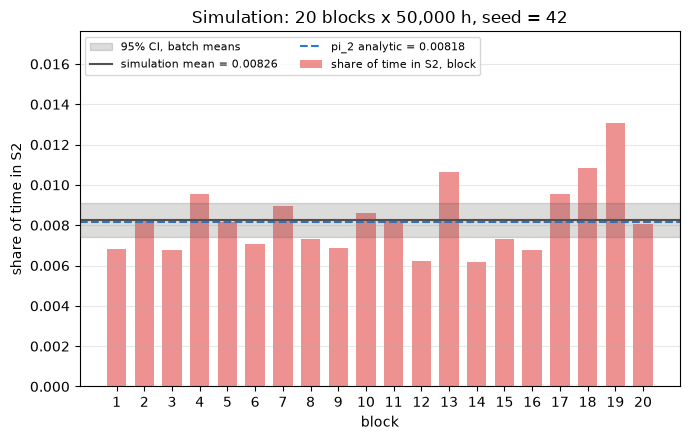

In [50]:
fig, ax = plt.subplots(figsize=(7, 4.5))
blocks = np.arange(1, N_BLOCKS + 1)
ax.bar(blocks, f_down, color=S2_COLOR, alpha=0.6, width=0.7, label="share of time in S2, block")
ax.axhspan(pi2_hat - pi2_half, pi2_hat + pi2_half, color=INK, alpha=0.2, zorder=3, label="95% CI, batch means")
ax.axhline(pi2_hat, color=INK, lw=1.5, label=f"simulation mean = {pi2_hat:.5f}")
ax.axhline(pi[DOWN], color=SCENARIO_COLOR, ls="--", lw=1.5, label=f"pi_2 analytic = {pi[DOWN]:.5f}")
ax.set_title(f"Simulation: {N_BLOCKS} blocks x {SIM_HORIZON // N_BLOCKS:,} h, seed = {SEED}")
ax.set_xlabel("block")
ax.set_ylabel("share of time in S2")
ax.set_xticks(blocks)
ax.set_ylim(0, f_down.max() * 1.35)
ax.grid(alpha=0.3, axis="y")
ax.legend(fontsize=8, loc="upper left", ncol=2)
plt.tight_layout()
plt.show()

Аналітичне $\pi_2 = 0{,}00818$ лежить усередині блокового 95 % інтервалу $[0{,}00743;\ 0{,}00908]$, оцінка імітації $0{,}00826$, абсолютна похибка $7 \cdot 10^{-5}$ (0,9 %). У годинах простою це 5,95 год/міс з інтервалом $[5{,}35;\ 6{,}54]$ проти аналітичних 5,89. Частки S0 і S1 теж потрапили у свої інтервали.

Півширина інтервалу $\pm 10$ % від $\pi_2$ визначається кількістю відмов (1 790 за $10^6$ год), а не кількістю годин, бо S2 -- рідкісний стан. Автокореляція сусідніх блоків 0,07, тобто блоки практично незалежні, і метод блоків застосовано коректно. Імітація використовує лише інтенсивності $q_{ij}$, а не `expm` чи систему $\pi Q = 0$, тому збіг незалежно підтверджує аналітичний результат.

## 8. Висновок

### Прогноз і результат

| Прогноз (розділ 1) | Результат | Оцінка |
|---|---|---|
| Домінує S0 (80-85 %), S1 близько 15 %, S2 < 1 % | $\pi = (0{,}832;\ 0{,}160;\ 0{,}0082)$ | збігся |
| $+25$ % до $q_{21}$ зменшить простій приблизно на 20 % | $5{,}89 \to 4{,}72$ год/міс, $-19{,}9$ % | збігся |
| $A(t)$ спадає від 1, і $A(24)$ трохи вища за $A_\infty$ | $A(24) = 0{,}9925 > A_\infty = 0{,}9918$ | збігся |

### Рекомендація власнику сервісу / SRE

| | $q_{21}$, 1/год | $A_\infty$ | Простій, год/міс |
|---|---|---|---|
| база | 0,215 | 99,18 % | 5,89 |
| сценарій $+25$ % | 0,269 | 99,34 % | 4,72 |

За поточних інтенсивностей gateway доступний 99,18 % часу і простоює в середньому 5,89 год на місяць. Прискорення відновлення з S2 на 25 % (автоматичний перезапуск або failover, швидший rollback, runbook для on-call) зменшує простій на 1,17 год/міс (-20 %). Його варто впроваджувати, якщо вартість заходів нижча за ціну 1,17 год простою на місяць. Але навіть після нього $A_\infty = 99{,}34$ % не досягає, наприклад, SLO 99,5 % (3,6 год/міс). Оскільки $\pi_2 / \pi_1 = q_{12}/q_{21}$, такий самий ефект дає і зменшення $q_{12}$ на 20 %, тобто запобігання переходу деградації у відмову. Тому для досягнення SLO варто поєднати швидше відновлення з алертом на тривале перебування в S1.

### Виробничі дані

- Джерело подій: synthetic health-check (наприклад, blackbox exporter, `probe_success`), метрики gateway в Prometheus (частка 5xx, p95 затримки) і журнал інцидентів для звірки моментів відмов і відновлень.
- Правило класифікації: з розділу 1, щохвилинне вікно, пріоритет S2 → S1 → S0. Оцінки $\hat q_{ij} = N_{ij}/T_i$, як у навчальному прикладі.
- Мінімальний період спостереження -- 12 місяців. Переходів S0 → S1 близько 15 на місяць, а S1 → S2 лише 1,3, тож за рік буде близько 15 відмов, і відносна похибка $\hat q_{12}$ та $\hat q_{21}$ становитиме близько $1/\sqrt{15} \approx 26$ %.

### Межі застосування

- Час перебування вважається експоненційним. Реальна тривалість відмов часто має важкий хвіст (рідкісні багатогодинні інциденти), тому $A(t)$ і розкид простою можуть відрізнятися від моделі.
- Інтенсивності сталі, тоді як у реальності вони залежать від навантаження, години доби і деплоїв. Для таких періодів потрібні окремі $Q$ або неоднорідна модель.
- $D_{month} = 720\,\pi_2$ -- середнє за довгий період. За 1,3 відмови на місяць фактичний простій окремого місяця сильно коливається, і частина місяців матиме 0 або 3+ відмов.
- S1 зараховано до доступних, хоча клієнти 115 год/міс бачать деградацію. Для SLO за затримкою S1 треба враховувати окремо.
- Усі інтенсивності синтетичні, і висновки стануть робочими лише після оцінювання $Q$ за виробничими даними.

## 9. Декларація використання ШІ

Генеративний ШІ (Claude, Anthropic) використано для  покращення візуалізацій та графіків, для оформлення таблиць, для покращення читабельності тексту, та коментарів і документацій у коді.

Запозиченого коду немає.